# Pendulum Control: Optimization, Imitation Learning & Evaluation

**Meroe Asgharbeigi · executed experiment, 28 October 2026**

Can a supervised neural policy approximate an optimization-based controller, and does offline action accuracy translate to stable closed-loop behavior?

The implementation is in `src/experiment.py`. Run `python -m src.experiment` from the repository root to regenerate demonstrations, fit models, evaluate controllers and export figures. This notebook executes the analysis of those recorded artifacts; it does not repeat the expensive simulation on every opening. All displayed results come from the completed run, not hand-written examples.

The original assignment notebook is preserved under `docs/original_notebook.ipynb`. This version uses scikit-learn's MLPRegressor rather than the original PyTorch/skorch wrapper, with a small, explicit validation search.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.experiment import check_dynamics, regression_metrics

ROOT = Path.cwd()
assert (ROOT / "results/run_manifest.json").exists(), "Run python -m src.experiment first, from the repository root"
manifest = json.loads((ROOT / "results/run_manifest.json").read_text())
manifest

Out[1]: 
{'config': {'seed': 42,
  'gravity': 9.81,
  'dt': 0.05,
  'steps': 200,
  'expert_episodes': 36,
  'horizon': 16,
  'de_iterations': 10,
  'de_popsize': 5,
  'evaluation_per_scenario': 20,
  'bootstrap_replicates': 2000},
 'selected_model': 'MLP 64x64',
 'mlp_iterations': 250,
 'mlp_iteration_limit': 250,
 'split_episodes': {'test': 7, 'train': 22, 'validation': 7},
 'rows': 7200,
 'versions': {'python': '3.12.14',
  'numpy': '2.5.4',
  'pandas': '3.1.0',
  'scipy': '1.18.1',
  'scikit_learn': '1.9.1',
  'gymnasium': '1.4.0'},
 'notes': ['Single training seed; confidence intervals describe evaluation initial states only.',
  'Near-upright training is not general swing-up training.',
  'Latency is machine-dependent; no real-time guarantee.']}


## 1. Simulator and problem boundaries

Observations are cosine/sine of angle and angular velocity; actions are torque clipped to [-2, 2]. Each episode lasts 200 steps. Higher cumulative reward is better, with zero as the theoretical upper bound. The MPC planner uses vectorized Pendulum dynamics to avoid constructing an environment inside every objective evaluation.

The next check compares 100 random physical states/actions against Gymnasium for both transitions and rewards. This checks simulator agreement, not global optimality of the finite-budget optimizer.

In [2]:
check_dynamics()
print("PASS: 100 one-step transition/reward comparisons against Gymnasium")

PASS: 100 one-step transition/reward comparisons against Gymnasium


## 2. Demonstration data and leakage control

36 expert episodes begin within ±20 degrees and ±0.1 rad/s. Every trajectory is retained, including poor control outcomes. A fixed permutation assigns 22 training, 7 validation and 7 test episodes. Entire episodes stay in one split; adjacent time steps cannot leak across partitions. StandardScaler is fit only on training rows inside each model pipeline.

This is a near-upright stabilization dataset. It does not establish general swing-up ability from the downward position.

,episodes,rows
split,,
test,7,1400
train,22,4400
validation,7,1400


,cos_theta,sin_theta,theta_dot,torque,reward
count,7200.000,7200.000,7200.000,7200.000,7200.000
mean,0.999,-0.003,-0.001,0.016,-0.003
std,0.004,0.038,0.108,0.794,0.010
min,0.946,-0.323,-0.566,-1.997,-0.113
25%,1.000,-0.011,-0.066,-0.517,-0.002
50%,1.000,-0.004,-0.000,0.037,-0.001
75%,1.000,0.006,0.066,0.512,-0.001
max,1.000,0.324,0.685,1.982,-0.000


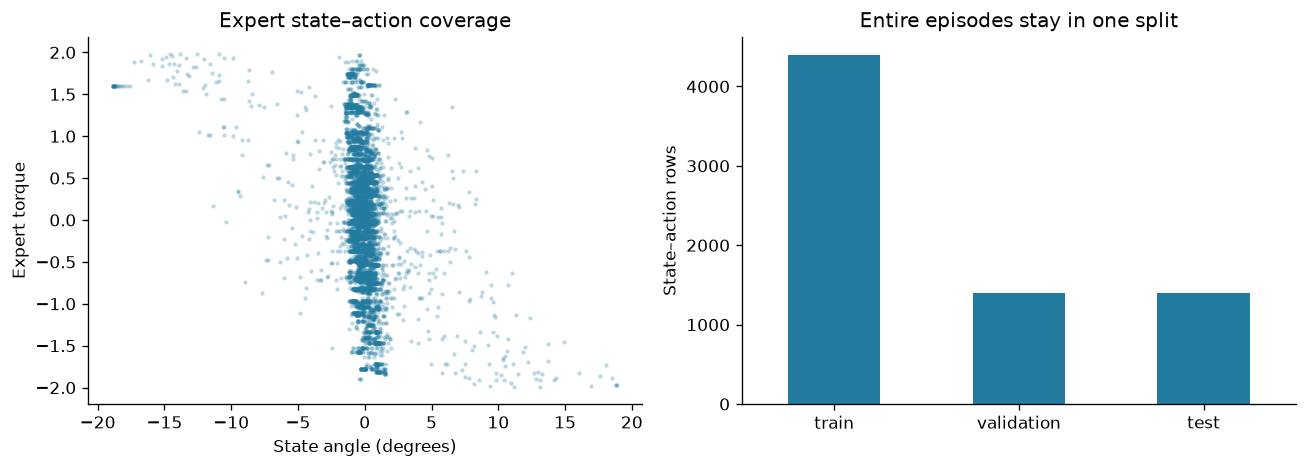

In [3]:
demonstrations = pd.read_csv(ROOT / "results/demonstrations.csv")
assert demonstrations.groupby("episode").split.nunique().max() == 1
display(demonstrations.groupby("split").agg(episodes=("episode", "nunique"), rows=("step", "size")))
display(demonstrations[["cos_theta", "sin_theta", "theta_dot", "torque", "reward"]].describe().round(3))
display(Image(filename=str(ROOT / "images/dataset_coverage.png")))

## 3. Model selection and supervised evaluation

Compare a constant mean-action regressor, standardized Ridge regression and two tanh MLPs (32×32 and 64×64 hidden units). Choose the neural architecture by validation torque RMSE, then evaluate it once on untouched test episodes. The chosen model is not refit on validation or test data. All predictions are clipped to actuator bounds before scoring.

The MLP uses Adam, alpha=0.01, learning rate=0.001, batch size 128 and at most 250 iterations. Hitting the cap is a convergence limitation, not evidence of an optimal model. Offline metrics quantify imitation of this finite-budget MPC, not optimal control.

Selected: MLP 64x64
MLP iterations: 250 / 250


,model,MAE,RMSE,R2
0,Mean action,0.6300,0.7955,-0.0008
1,Ridge,0.4827,0.5883,0.4526
2,MLP 32x32,0.4268,0.5350,0.5474
3,MLP 64x64,0.4230,0.5318,0.5526


,model,split,MAE,RMSE,R2
0,Mean action,train,0.6269,0.7915,0.0000
1,Mean action,validation,0.6300,0.7955,-0.0008
2,Mean action,test,0.6393,0.8024,-0.0004
3,Ridge,train,0.4721,0.5743,0.4735
4,Ridge,validation,0.4827,0.5883,0.4526
5,Ridge,test,0.4758,0.5811,0.4753
6,Neural network,train,0.4058,0.5093,0.5860
7,Neural network,validation,0.4230,0.5318,0.5526
8,Neural network,test,0.4175,0.5177,0.5835


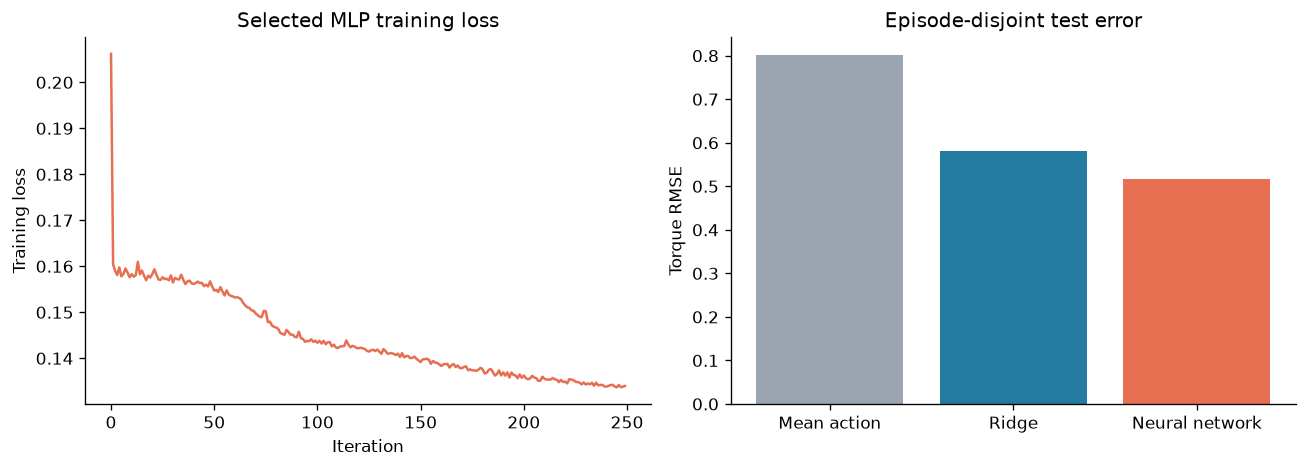

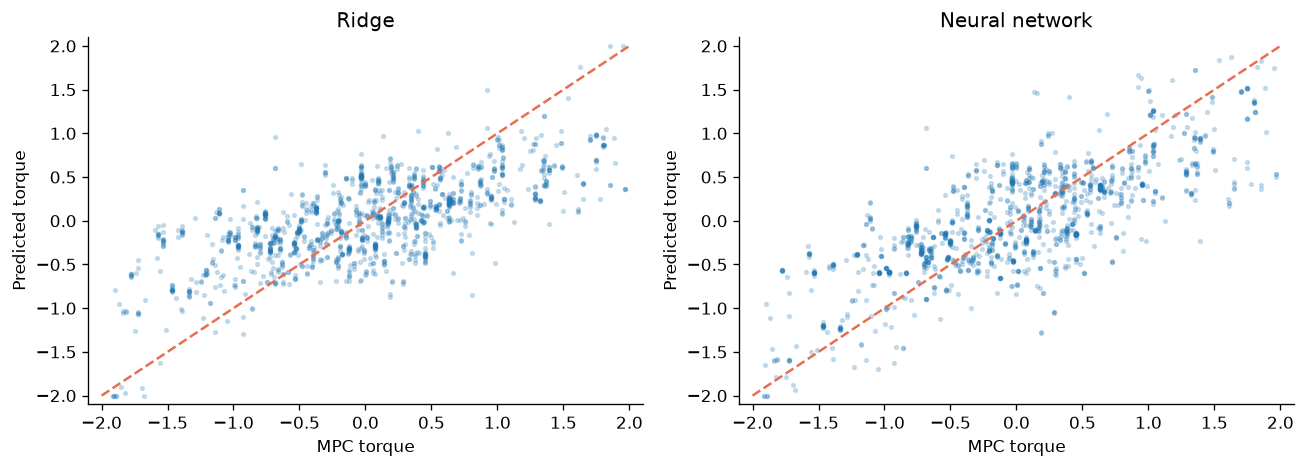

In [4]:
validation = pd.read_csv(ROOT / "results/validation.csv")
metrics = pd.read_csv(ROOT / "results/regression_metrics.csv")
display(validation.round(4))
print("Selected:", manifest["selected_model"])
print("MLP iterations:", manifest["mlp_iterations"], "/", manifest["mlp_iteration_limit"])
display(metrics.round(4))
display(Image(filename=str(ROOT / "images/model_evaluation.png")))
display(Image(filename=str(ROOT / "images/predicted_vs_actual.png")))

## 4. Paired closed-loop evaluation

Six controllers run on the same 20 initial states per scenario: Random, Zero torque, Mean action, Ridge, Neural network and MPC. Evaluation seeds are distinct from demonstration seeds. Near-upright states use the training initial-state range; a wider scenario uses ±90 degrees and ±1 rad/s. Every policy is evaluated in the actual Gymnasium environment, without retuning on the evaluation results.

Metrics include total reward, final absolute post-action angle, mean torque, and fraction of steps with |angle|<10° **and** |angular velocity|<0.5 rad/s. The plots use 2,000-resample percentile bootstrap intervals over episodes. The paired difference intervals resample matched episode differences; they do not measure uncertainty across retraining seeds.

,scenario,controller,n,mean_score,ci_low,ci_high,upright_fraction,median_latency_ms
0,Near upright,MPC,20,-0.540,-0.708,-0.408,0.991,8.766
1,Near upright,Mean action,20,-652.456,-689.183,-611.537,0.087,0.004
2,Near upright,Neural network,20,-0.260,-0.415,-0.135,0.991,0.017
3,Near upright,Random,20,-890.262,-927.001,-855.921,0.035,0.005
4,Near upright,Ridge,20,-0.261,-0.411,-0.136,0.992,0.007
5,Near upright,Zero torque,20,-552.812,-601.425,-505.135,0.205,0.004
6,Wider initial states,MPC,20,-74.526,-99.284,-44.229,0.896,8.933
7,Wider initial states,Mean action,20,-880.338,-972.551,-781.261,0.045,0.004
8,Wider initial states,Neural network,20,-707.942,-950.248,-422.553,0.393,0.016
9,Wider initial states,Random,20,-995.732,-1053.212,-938.108,0.014,0.006


,scenario,contrast,mean_difference,ci_low,ci_high
0,Near upright,Neural network minus Random,890.002,855.658,926.689
1,Near upright,Neural network minus Zero torque,552.552,504.983,600.932
2,Near upright,Neural network minus Ridge,0.001,-0.020,0.022
3,Near upright,Neural network minus MPC,0.280,0.258,0.302
4,Wider initial states,Neural network minus Random,287.790,83.709,517.615
5,Wider initial states,Neural network minus Zero torque,167.540,10.467,342.681
6,Wider initial states,Neural network minus Ridge,-367.236,-577.941,-167.088
7,Wider initial states,Neural network minus MPC,-633.416,-851.118,-378.773


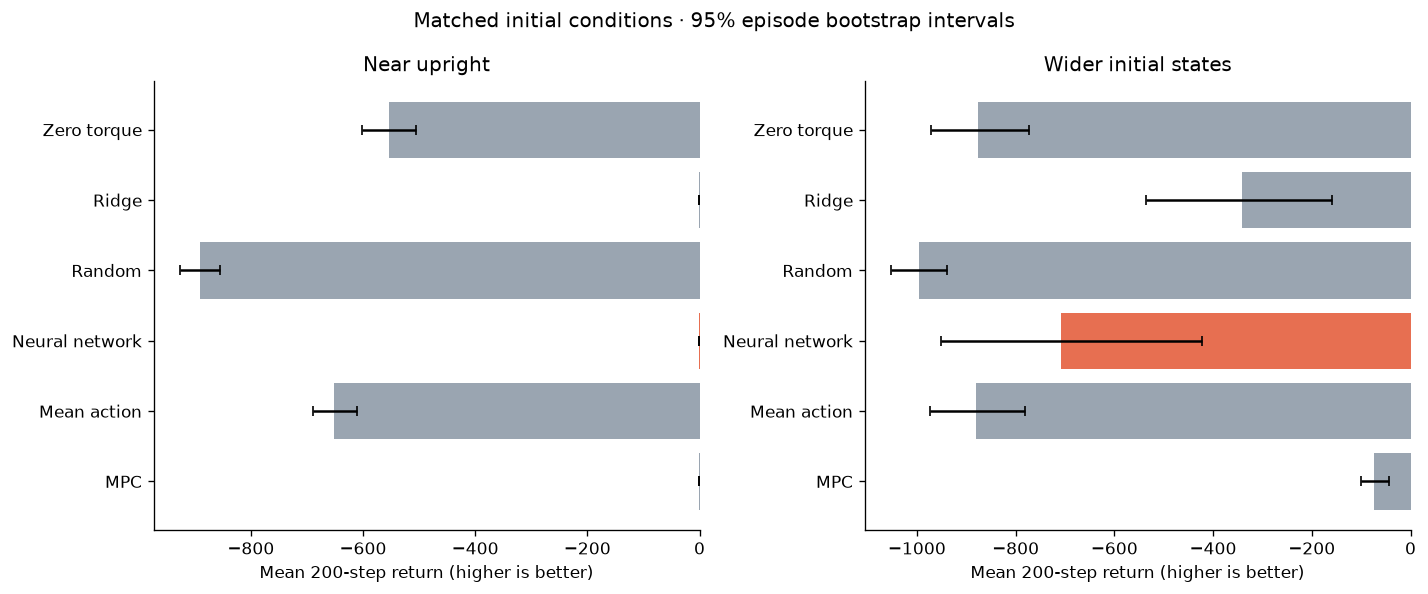

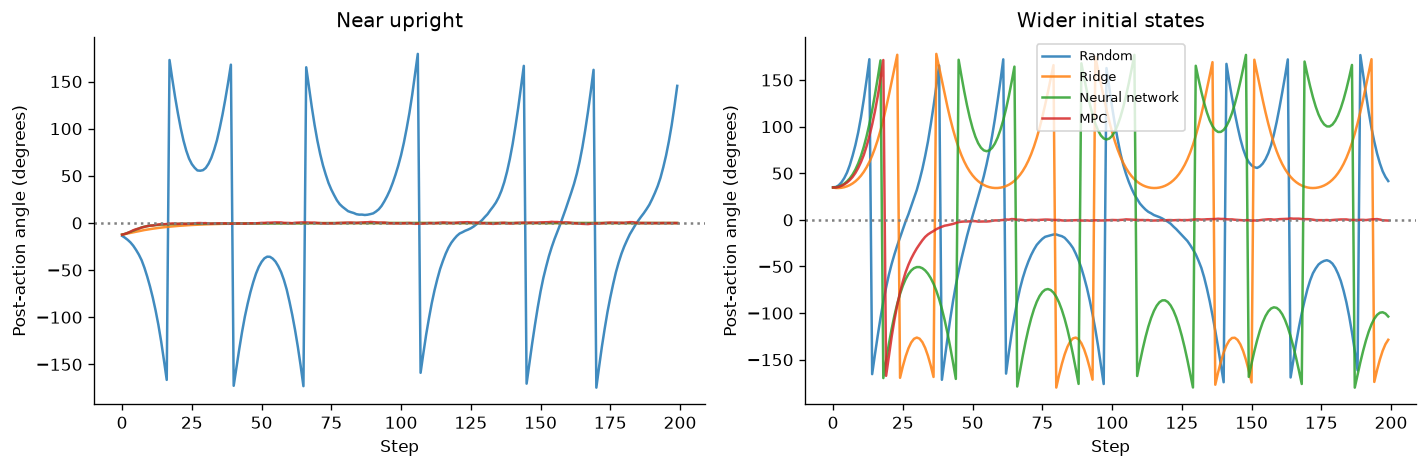

In [5]:
episodes = pd.read_csv(ROOT / "results/controller_episodes.csv")
summary = pd.read_csv(ROOT / "results/controller_summary.csv")
differences = pd.read_csv(ROOT / "results/paired_differences.csv")
display(summary.round(3))
display(differences.round(3))
display(Image(filename=str(ROOT / "images/controller_comparison.png")))
display(Image(filename=str(ROOT / "images/example_trajectories.png")))

## 5. Reproducibility and artifact verification

The recorded test predictions allow independent recomputation of MAE, RMSE and R². The trained policy is exported as numerical arrays in `results/policy_weights.npz`; no pickle loading is required. Regression tests additionally check saved-weight predictions, matched scenarios and episode separation.

Latency compares a NumPy forward pass matching the fitted models against the MPC optimizer and simple baselines, including action clipping. It is hardware-dependent, measured serially with no warm-up protocol, and is not a real-time or production benchmark.

PASS: exported predictions reproduce all test metrics


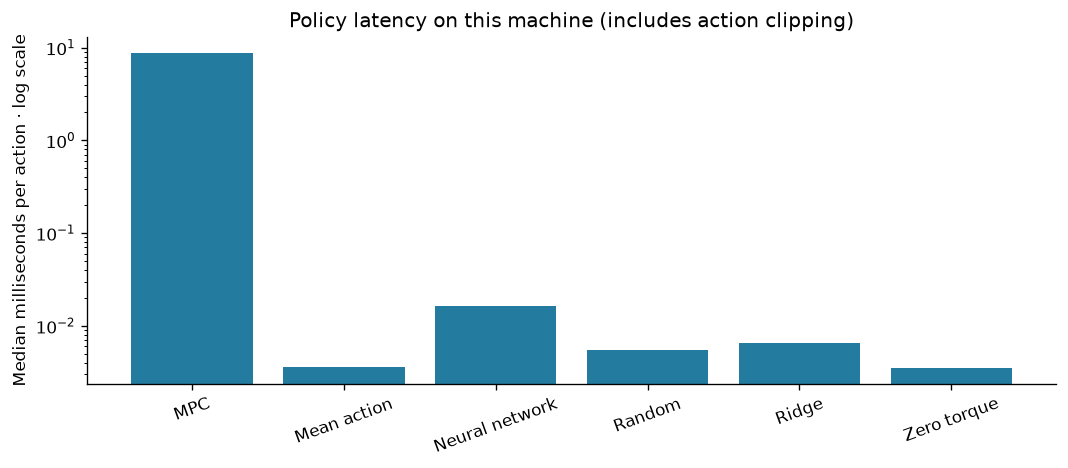

python          3.12.14
numpy             2.5.4
pandas            3.1.0
scipy            1.18.1
scikit_learn      1.9.1
gymnasium         1.4.0
Name: Recorded environment, dtype: str

In [6]:
predictions = pd.read_csv(ROOT / "results/test_predictions.csv")
for name, frame in predictions.groupby("model"):
    recorded = metrics[(metrics.model == name) & (metrics.split == "test")].iloc[0]
    for key, value in regression_metrics(frame.actual, frame.predicted).items():
        assert np.isclose(value, recorded[key], atol=1e-10)
print("PASS: exported predictions reproduce all test metrics")
display(Image(filename=str(ROOT / "images/policy_latency.png")))
display(pd.Series(manifest["versions"], name="Recorded environment"))

## 6. Conclusions and next experiments

The selected 64×64 MLP has test torque RMSE 0.518 versus Ridge 0.581. Both maintain approximately 99% upright time on the near-upright evaluation. Their paired mean-return difference is 0.0009, with a 95% interval [-0.0204, 0.0219]: this experiment does not establish a neural-policy advantage over Ridge there.

With wider initial states, the neural policy has mean return -707.94, Ridge -340.71 and MPC -74.53. Neural minus Ridge is -367.24, with a paired 95% interval [-577.94, -167.09]. Better offline imitation does not ensure better control outside the demonstration initial-state range. These are conditional results from one training seed and the specified scenarios.

Interpret the measured tables rather than assuming a neural network wins. Compare both offline error and closed-loop stability: feedback changes the state distribution, and a policy can drift away from its demonstration states. The wider-state scenario tests that vulnerability, but is not an exhaustive robustness study.

Limits: one demonstration/model training seed; seven test demonstration episodes; 20 evaluation initial states per scenario; an approximate expert with fixed optimization budget; no process/sensor noise, domain randomization, hardware experiment or general swing-up guarantee. MLP candidates reached their iteration limit in this run.

Next steps: repeat training across independent seeds; compare optimizer budgets and warm-started MPC; add DAgger-style on-policy expert labels; test noise/model mismatch; use a separate validation scenario set before changing policy settings.